# Kinematic slip on a graded triangular mesh, step 2: the Bayesian inversion with AlTar

[Step 1](step1_mesh.ipynb) made kinematic_mesh's synthetic on a mesh graded by gmsh. This notebook runs the same cascaded inversion: the static data first, then the waveforms, with the slips, the rise times, a rupture velocity for each group of patches and the hypocenter. It compares the posterior with the truth, and with the same inversion of kinematic_mesh's data on its regular mesh.

The sampler is the one the guide recommends, not kinematic_mesh's longer run: HMC walks until the chains decorrelate, a mass matrix pooled over 16 β steps, and 160 more walks at β = 1, with 512 chains, about an hour on one GPU. The regular mesh's results, in `regular/`, come from the same sampler on kinematic_mesh's inputs.

The cells that run AlTar skip their run if its results are in `results/` already.

In [1]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

def load(inputs, results):
    # a mesh, its truth, and the posterior and its fit
    out = {}
    with h5py.File(f'{inputs}/mesh.h5') as h5:
        out['V'], out['F'], out['uv'] = (np.asarray(h5[k]) for k in ['vertices', 'faces', 'uv'])
        out['groups'] = np.asarray(h5['groups/velocity'])
    with h5py.File(f'{inputs}/synthetic.h5') as h5:
        out['true'] = {k: np.asarray(v) for k, v in h5['true'].items()}
        out['mu'], out['area'] = np.asarray(h5['mu']), np.asarray(h5['area'])
    if os.path.exists(f'{results}/step_final.h5'):
        names = ['across', 'parallel', 'risetime', 'rupturevelocity', 'hypo_strike', 'hypo_dip']
        with h5py.File(f'{results}/step_final.h5') as h5:
            P = h5['ParameterSets']
            post = {s: np.asarray(P[f'{s}_physical'] if f'{s}_physical' in P else P[s], dtype=float) for s in names}
        post['hypocenter'] = np.column_stack([post.pop('hypo_strike')[:, 0], post.pop('hypo_dip')[:, 0]])
        out['post'] = post
    return out

def summary(run):
    # the beta steps of a run, and its acceptance rates, from its BetaStatistics.txt
    stats = np.loadtxt(f'{run}/BetaStatistics.txt', delimiter=',', skiprows=1)[1:]
    acceptance = stats[:, 3] / stats[:, 3:].sum(1)
    print(f"{run}: {int(stats[-1, 0])} beta steps to beta = {stats[-1, 1]:g}; acceptance rate {acceptance.min():.2f} to {acceptance.max():.2f}")

## The static inversion

The slips from the GPS and the line of sight alone, with the priors of kinematic_mesh: along the convergence U(-1, 15) m, across it N(0, 0.5) m.

In [2]:
print(open('static.pfg').read())

; step 2, the static inversion: the slips from the static data alone, gps and line of sight; the
; priors of Gombert et al. (2018), slip along the convergence U(-1, 15) m, across it N(0, 0.5) m
slipmodel:
    model = altar.models.seismic.static
    model:
        case = input
        patches = 131
        parameters = 2*{slipmodel.model.patches}
        green = static.gf.h5
        dataobs:
            observations = 188
            data_file = static.data.h5
            cd_file = static.Cd.h5
        ; the columns of the green's functions: across, then along the convergence
        psets_list = [across, parallel]
        psets:
            across = contiguous
            parallel = contiguous
            across:
                count = {slipmodel.model.patches}
                prior = gaussian
                prior.mean = 0
                prior.sigma = 0.5
            parallel:
                count = {slipmodel.model.patches}
                prior = uniform
                prior.sup

In [3]:
if not os.path.exists('results/static/step_final.h5'):
    !slipmodel.plexus sample --config=static.pfg > static.log 2>&1
summary('results/static')

results/static: 74 beta steps to beta = 1; acceptance rate 0.69 to 0.73


## The cascaded inversion

The ensemble of the static model, at β = 1 throughout, and the kinematic model on triangles, annealed; the slips start from the static posterior. The hypocenter's prior is centered 5 km from the true one, as a catalog's might be.

In [4]:
print(open('cascaded.pfg').read())

; step 2, the cascaded inversion: the static data at beta = 1 throughout, the waveforms annealed; the
; slips start from the static posterior; a rise time per patch, a rupture velocity per group of
; patches, and the hypocenter, with a prior 5 km off the true one, as a catalog's might be
slipmodel:
    model = altar.models.ensemble
    model:
        case = input
        patches = 131
        psets_list = [across, parallel, risetime, rupturevelocity, hypo_strike, hypo_dip]
        psets:
            across = contiguous
            parallel = contiguous
            risetime = contiguous
            rupturevelocity = contiguous
            hypo_strike = contiguous
            hypo_dip = contiguous
            across:
                count = {slipmodel.model.patches}
                prep = preset
                prep.input_file = results/static/step_final.h5
                prep.dataset = ParameterSets/across
                prior = gaussian
                prior.mean = 0
                

In [5]:
if not os.path.exists('results/cascaded/step_final.h5'):
    !slipmodel.plexus sample --config=cascaded.pfg > cascaded.log 2>&1
summary('results/cascaded')
summary('regular/results/cascaded')

results/cascaded: 73 beta steps to beta = 1; acceptance rate 0.41 to 0.72
regular/results/cascaded: 73 beta steps to beta = 1; acceptance rate 0.38 to 0.71


## The fit to the data

The `forward` action runs the models on the posterior mean and on the posterior samples, each on its own data; its output keeps the predictions and the slip history of the mean model.

In [6]:
if not os.path.exists('results/cascaded/forward.h5'):
    !slipmodel.plexus forward --config=cascaded.pfg --slipmodel.forward.theta=results/cascaded/step_final.h5 \
        --slipmodel.forward.output=results/cascaded/forward.h5 --slipmodel.forward.samples=2000 > forward.log 2>&1
for label, path in [('gmsh mesh', 'results/cascaded/forward.h5'), ('regular mesh', 'regular/results/cascaded/forward.h5')]:
    with h5py.File(path) as h5:
        fits = []
        for model in ['kinematic', 'static']:
            d, p = np.asarray(h5[f'{model}/data/observed']), np.asarray(h5[f'{model}/data/mean_model'])
            chi2 = float(h5[f'{model}/fit/mean_model/chi2'][()]) / float(h5[f'{model}/fit/observations'][()])
            fits.append(f"{model} chi-square per datum {chi2:.2f}, variance reduction {1 - ((d - p) ** 2).sum() / (d ** 2).sum():.4f}")
    print(f"{label}: " + '; '.join(fits))

gmsh mesh: kinematic chi-square per datum 1.01, variance reduction 0.9902; static chi-square per datum 0.73, variance reduction 0.9995
regular mesh: kinematic chi-square per datum 1.03, variance reduction 0.9900; static chi-square per datum 0.64, variance reduction 0.9996


## The posterior against the truth, on both meshes

The errors of the posterior mean against the truth, patch by patch, and weighted by the areas of the patches, since the triangles of the graded mesh differ in size by a factor of 6; the share of the true values within the 68% interval of their posterior; the moment magnitude; the rupture velocities and the hypocenter.

In [7]:
meshes = {'gmsh': load('input', 'results/cascaded'), 'regular': load('regular/input', 'regular/results/cascaded')}
magnitude = lambda m, slip: 2 / 3 * (np.log10((m['mu'] * m['area'] * 1e6 * slip).sum(-1)) - 9.1)
rows = []
for name, m in meshes.items():
    t, p = m['true'], m['post']
    w = m['area'] / m['area'].sum()
    mean = {s: v.mean(0) for s, v in p.items()}
    lo, hi = np.percentile(p['parallel'], [16, 84], axis=0)
    Mw = magnitude(m, np.hypot(p['across'], p['parallel']))
    rows.append((name, len(m['F']), np.corrcoef(mean['parallel'], t['parallel'])[0, 1],
                 np.sqrt(((mean['parallel'] - t['parallel']) ** 2).mean()), np.sqrt((w * (mean['parallel'] - t['parallel']) ** 2).sum()),
                 ((lo <= t['parallel']) & (t['parallel'] <= hi)).mean(), np.median(p['parallel'].std(0)),
                 np.sqrt(((mean['across'] - t['across']) ** 2).mean()), np.sqrt(((mean['rupturevelocity'] - t['rupturevelocity']) ** 2).mean()),
                 f"{Mw.mean():.3f} ± {Mw.std():.3f}", magnitude(m, np.hypot(t['across'], t['parallel'])),
                 f"{mean['hypocenter'][0]:.1f} ± {p['hypocenter'][:, 0].std():.1f}, {mean['hypocenter'][1]:.1f} ± {p['hypocenter'][:, 1].std():.1f}"))
labels = ['patches', 'slip along: correlation', 'rms error (m)', 'rms error, area weighted (m)', 'within 68%', 'median sd (m)',
          'slip across: rms error (m)', 'velocities: rms error (km/s)', 'Mw', 'true Mw', 'hypocenter (true 125.0, 55.0)']
formats = ['{:d}', '{:.3f}', '{:.3f}', '{:.3f}', '{:.0%}', '{:.3f}', '{:.3f}', '{:.2f}', '{}', '{:.3f}', '{}']
print(f"{'':32s}" + ''.join(f"{r[0]:>24s}" for r in rows))
for k, (label, fmt) in enumerate(zip(labels, formats)):
    print(f"{label:32s}" + ''.join(f"{fmt.format(r[k + 1]):>24s}" for r in rows))

                                                    gmsh                 regular
patches                                              131                     128
slip along: correlation                            0.971                   0.980
rms error (m)                                      0.271                   0.229
rms error, area weighted (m)                       0.227                   0.229
within 68%                                           79%                     84%
median sd (m)                                      0.277                   0.304
slip across: rms error (m)                         0.104                   0.117
velocities: rms error (km/s)                        0.51                    0.38
Mw                                         7.944 ± 0.005           7.964 ± 0.007
true Mw                                            7.899                   7.901
hypocenter (true 125.0, 55.0)    124.9 ± 1.0, 51.2 ± 1.4 124.9 ± 1.4, 52.5 ± 1.1


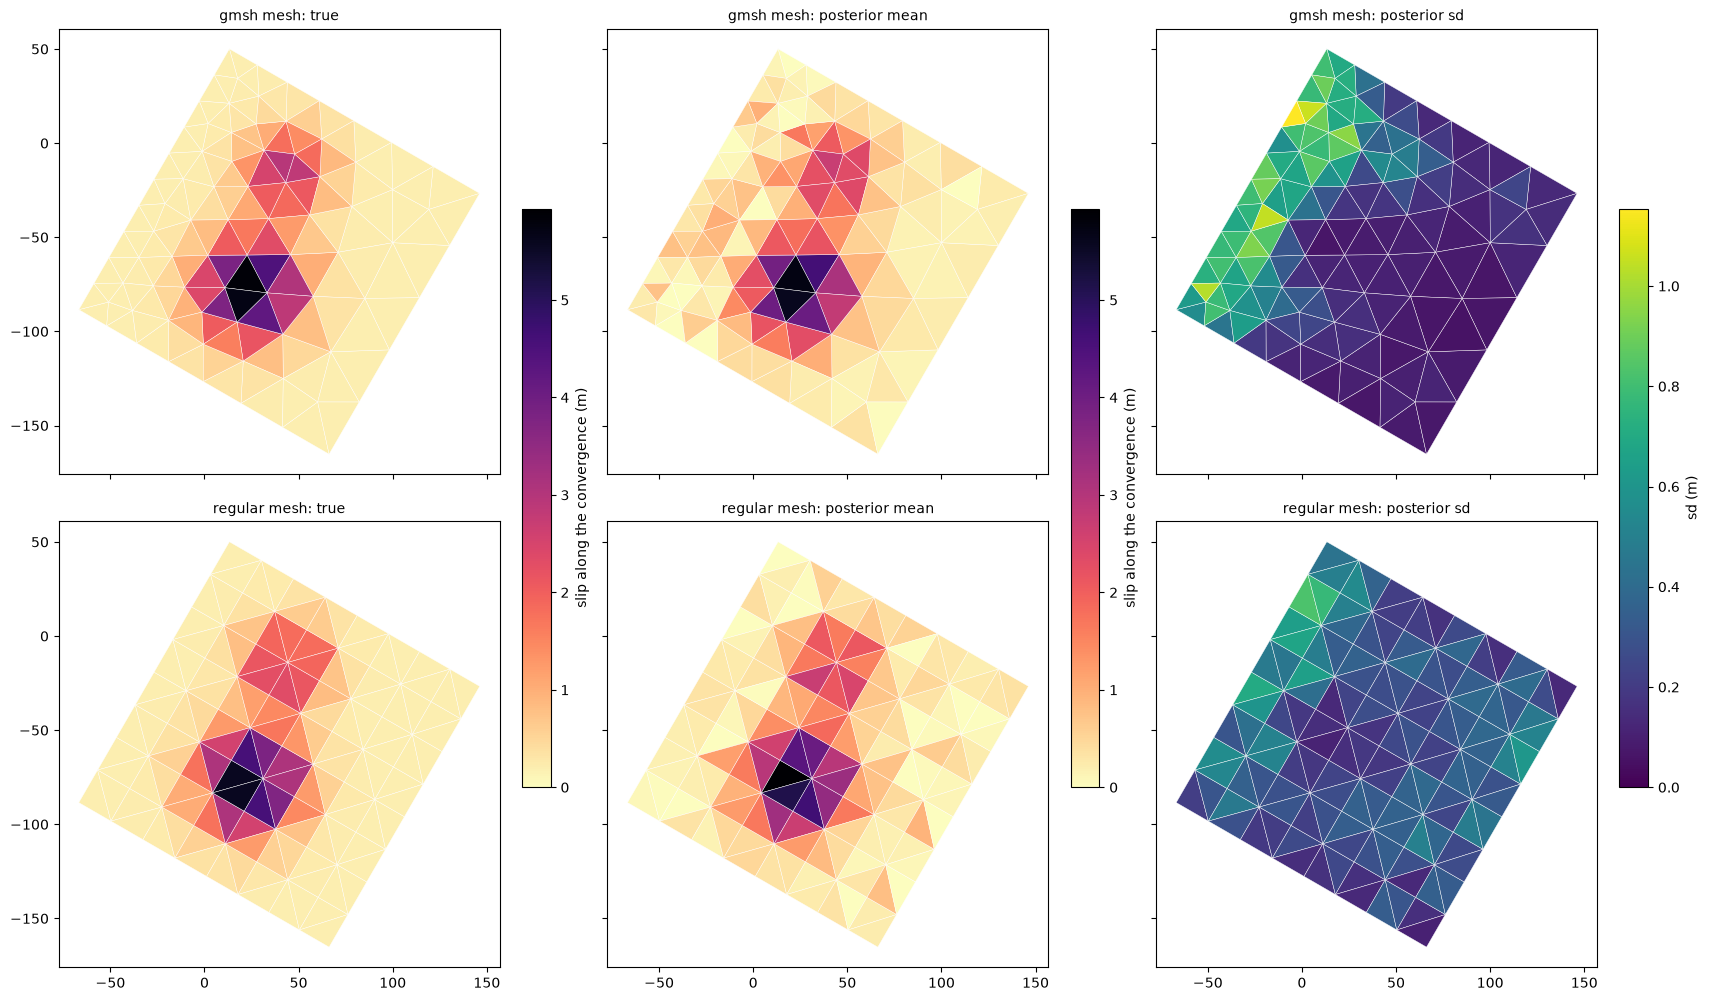

In [8]:
# the slip along the convergence: the truth, the posterior mean and its sd, on each mesh
fig, axes = plt.subplots(2, 3, figsize=(17, 10), sharex=True, sharey=True, layout='constrained')
hi = max(max(m['true']['parallel'].max(), m['post']['parallel'].mean(0).max()) for m in meshes.values())
sdmax = max(m['post']['parallel'].std(0).max() for m in meshes.values())
for row, (name, m) in enumerate(meshes.items()):
    V, F = m['V'], m['F']
    for col, (values, title, cmap, top) in enumerate([(m['true']['parallel'], 'true', 'magma_r', hi),
                                                      (m['post']['parallel'].mean(0), 'posterior mean', 'magma_r', hi),
                                                      (m['post']['parallel'].std(0), 'posterior sd', 'viridis', sdmax)]):
        pc = axes[row, col].tripcolor(V[:, 0], V[:, 1], F, facecolors=values, cmap=cmap, vmin=0, vmax=top, edgecolors='w', lw=0.3)
        axes[row, col].set_title(f'{name} mesh: {title}', fontsize=10)
        axes[row, col].set_aspect('equal')
        if row == 1:
            fig.colorbar(pc, ax=axes[:, col], shrink=0.6, label='slip along the convergence (m)' if col < 2 else 'sd (m)')
plt.show()

Patch by patch, the graded mesh's errors are larger, but weighted by area they are the same: its many small triangles near the trench are each resolved less well than a larger one, while the slip they add up to is as well determined. Its slip errors against the area of the patches:

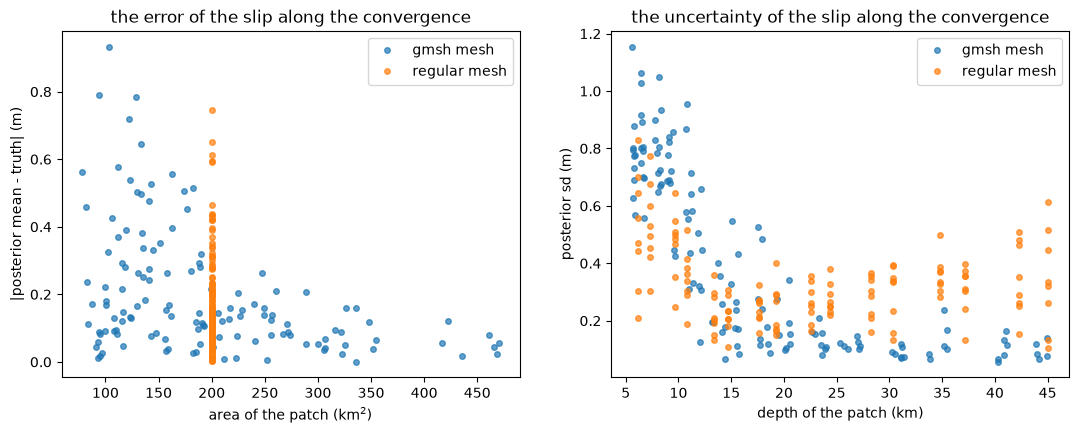

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, m in meshes.items():
    err = m['post']['parallel'].mean(0) - m['true']['parallel']
    depth = m['V'][m['F']][:, :, 2].mean(1)
    ax1.plot(m['area'], np.abs(err), 'o', ms=4, alpha=0.7, label=f'{name} mesh')
    ax2.plot(depth, m['post']['parallel'].std(0), 'o', ms=4, alpha=0.7, label=f'{name} mesh')
ax1.set_xlabel('area of the patch (km$^2$)'); ax1.set_ylabel('|posterior mean - truth| (m)'); ax1.legend()
ax1.set_title('the error of the slip along the convergence')
ax2.set_xlabel('depth of the patch (km)'); ax2.set_ylabel('posterior sd (m)'); ax2.legend()
ax2.set_title('the uncertainty of the slip along the convergence')
plt.show()

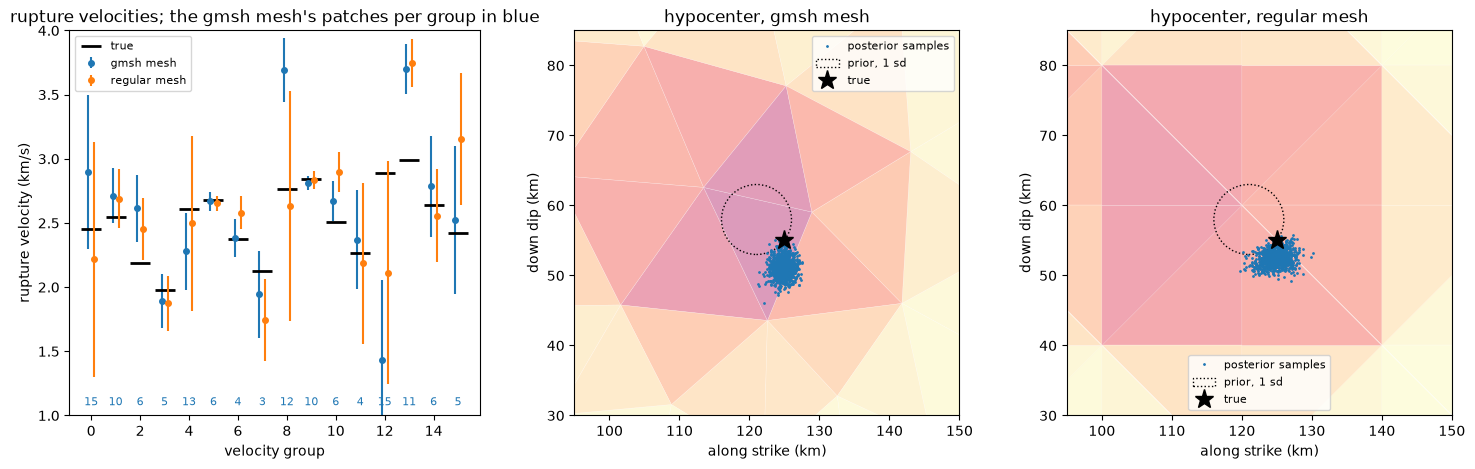

In [10]:
# the rupture velocities, with the number of patches of each group, and the hypocenter, on each mesh
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for k, (name, m) in enumerate(meshes.items()):
    v = m['post']['rupturevelocity']
    order = np.arange(v.shape[1])
    axes[0].errorbar(order + (k - 0.5) * 0.25, v.mean(0), yerr=v.std(0), fmt='o', ms=4, label=f'{name} mesh')
    if k == 0:
        axes[0].plot(order, m['true']['rupturevelocity'], 'k_', ms=14, mew=2, label='true')
        counts = np.bincount(m['groups'])
        for g in order:
            axes[0].annotate(f'{counts[g]}', (g, 1.08), ha='center', fontsize=8, color='C0')
    ax = axes[k + 1]
    ax.tripcolor(m['uv'][:, 0], m['uv'][:, 1], m['F'], facecolors=m['true']['parallel'], cmap='magma_r', edgecolors='w', lw=0.3, alpha=0.5)
    ax.plot(*m['post']['hypocenter'][::8].T, '.', ms=2, color='C0', label='posterior samples')
    ax.add_patch(plt.Circle((121.0, 58.0), 5.0, fill=False, ls=':', color='k', label='prior, 1 sd'))
    ax.plot(*m['true']['hypocenter'], 'k*', ms=14, label='true')
    ax.set_aspect('equal'); ax.set_xlim(95, 150); ax.set_ylim(30, 85)
    ax.set_xlabel('along strike (km)'); ax.set_ylabel('down dip (km)'); ax.set_title(f'hypocenter, {name} mesh'); ax.legend(fontsize=8)
axes[0].set_ylim(1, 4); axes[0].set_xlabel('velocity group'); axes[0].set_ylabel('rupture velocity (km/s)')
axes[0].set_title('rupture velocities; the gmsh mesh\'s patches per group in blue'); axes[0].legend(loc='upper left', fontsize=8)
plt.show()

The rupture velocities are resolved where the fault slips: the groups that release more than 5% of the moment have the same errors on both meshes, 0.34 km/s. The graded mesh loses in the shallow groups near the trench, which slip little (about 2% of the moment each) and hold its many small triangles, 12 to 15 a group: there its posterior is sometimes narrow and off, e.g. group 8, 3.69 ± 0.25 km/s against a true 2.76, where the regular mesh's stays wide, near its prior. The deep groups, with 3 to 5 large triangles, are recovered as well as on the regular mesh. Group 13, too fast on both meshes, and the hypocenter, up dip of the true one on both, are the trade-off between the two that the stations, on land east of the rupture, leave: not the mesh.

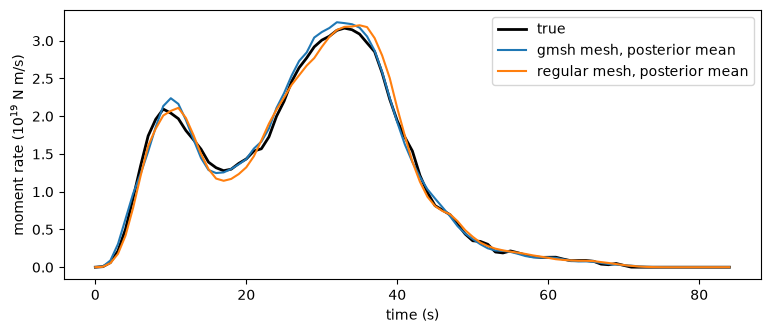

In [11]:
# the moment rate, of the slip along the convergence
fig, ax = plt.subplots(figsize=(9, 3.5))
tk = None
for name, m in meshes.items():
    path = 'results/cascaded/forward.h5' if name == 'gmsh' else 'regular/results/cascaded/forward.h5'
    with h5py.File(path) as h5:
        Mb_post = np.asarray(h5['kinematic/Mb/mean']).reshape(m['true']['Mb'].shape)
    rate = lambda history: (m['mu'] * m['area'] * 1e6 * history[:, 1]).sum(1)
    tk = np.arange(Mb_post.shape[0])
    if name == 'gmsh':
        ax.plot(tk, rate(m['true']['Mb']) / 1e19, 'k', lw=2, label='true')
    ax.plot(tk, rate(Mb_post) / 1e19, label=f'{name} mesh, posterior mean')
ax.set_xlabel('time (s)'); ax.set_ylabel('moment rate (10$^{19}$ N m/s)'); ax.legend()
plt.show()

## Summary

- A mesh graded by gmsh, of nearly equilateral triangles from 17 km at the trench to 34 km at depth, works with AlTar's kinematic model on triangles as the regular one does: the same number of parameters, the same fit to the data, the same slip error weighted by area, and a moment magnitude a little closer to the truth.
- The rupture times on it are as accurate: the first-order solver runs about 0.3 s late on both, at the default refinement.
- Its small triangles are each resolved less well, and their posterior covers the truth slightly less often (79% within the 68% interval, against 84%).
- Its rupture velocities are as well resolved where the fault slips, but less in the shallow groups that slip little, where its small triangles are; there the posterior can be narrow and off, so the velocities of groups that release little moment are best not trusted on either mesh.

This slab unrolls onto a plane, so its surface coordinates are exact. A real slab, e.g. from Slab2, is curved along strike too; its surface coordinates, for the rupture front and the hypocenter, would need a flattening of the mesh.